In [21]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm

plt.rcParams["font.size"] = '10'

### Data availibility plot

In [22]:

data_dir = r"D:\!Work\IFA\!data\Urban_fluxes_NE\processed"

city_name = 'Moscow'
city_time_belt = 3
corr_name = ''

# city_name = 'Tomsk'
# corr_name = 'new_rot3'
# city_time_belt = 7

# city_name = 'Beijing'
# corr_name = ''
# city_time_belt = 8

df4sites = {}

file_pattern = data_dir + '/' + city_name + ('_' if corr_name else '') + corr_name + '/L1/*.csv'
display(file_pattern)

for file in glob.glob(file_pattern):
    site = os.path.basename(file).split('.')[0]
    print (file)
    df = pd.read_csv(file, index_col=0, parse_dates=True)
    df.index = df.index + pd.Timedelta(hours=city_time_belt)
    if site == 'ZNS_56m':
        df = df.drop(index=[i for i in df.index if i > pd.Timestamp (2022,2,1) and i < pd.Timestamp (2022,6,14)])
    df4sites[site] = df

print (df4sites.keys())

'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow/L1/*.csv'

D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\ERA5.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\MSU_11m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\MSU_19m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\MSU_2m.csv
D:\!Work\IFA\!data\Urban_fluxes_NE\processed/Moscow/L1\ZNS_56m.csv
dict_keys(['ERA5', 'MSU_11m', 'MSU_19m', 'MSU_2m', 'ZNS_56m'])


In [23]:
df = pd.DataFrame()

for site in df4sites.keys():
    df4site = df4sites[site].copy()
    df4site = df4site.rename(columns = {c: site + '_' + c for c in df4site.columns})
    df = df.merge(df4site, how = 'outer', right_index = True, left_index = True)

for col in [c for c in df.columns if 'ERA5' in c]: 
    df[col] = df[col].interpolate(method = 'linear')

display(df.head())

,ERA5_Qh,ERA5_Qle,ERA5_Qtau,ERA5_Ustar,ERA5_T_air,ERA5_RH_air,ERA5_P_air,ERA5_Rho_air,ERA5_Wind_U,ERA5_Wind_V,...,MSU_2m_qc_tot_ext,ZNS_56m_Qh,ZNS_56m_Qtau,ZNS_56m_Ustar,ZNS_56m_T_air,ZNS_56m_Rho_air,ZNS_56m_Wind_vel,ZNS_56m_Cd,ZNS_56m_qc_tot,ZNS_56m_qc_tot_ext
2020-01-01 03:00:00,-21.313334,4.920000,0.108551,0.300764,1.284576,94.23917,977.21436,1.242005,3.544800,-2.331009,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 04:00:00,-22.252500,4.668611,0.121990,0.318840,1.420319,95.16815,977.96564,1.242345,3.398743,-2.944183,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 05:00:00,-21.216110,7.905833,0.155424,0.359889,1.091217,93.23746,978.88060,1.245000,2.845902,-4.134308,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 06:00:00,-31.831388,6.499167,0.206088,0.414415,1.046783,93.21794,980.05560,1.246696,2.008301,-5.308685,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-01 07:00:00,-24.661388,18.435556,0.279859,0.482924,0.940826,91.84855,981.66626,1.249228,1.658112,-6.262360,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
pd.options.plotting.backend = "plotly"
df[['ZNS_56m_Qh', 'MSU_19m_Qh', 'ERA5_Qh']].plot()

In [16]:
plt.figure()

#sites = ['Beijing_47m', 'Beijing_80m', 'Xianghe_32m', 'Xianghe_80m']
sites = df4sites.keys()

for site in sites:
    vel   = df4sites[site]['Wind_vel'].where(df4sites[site]['qc_tot'] > 0)
    ustar = df4sites[site]['Ustar'].where(df4sites[site]['qc_tot'] > 0)

    plt.plot(vel, ustar, '.', label = site)
    plt.grid()
    plt.xlim((0, 20))
    plt.ylim((0, 2))

plt.legend()


KeyError: 'qc_tot'

<Figure size 640x480 with 0 Axes>

### Filter data and select days with low gaps ratio

['ERA5', 'MSU_11m', 'MSU_19m']

['ERA5', 'MSU_19m']

['ERA5', 'MSU_19m', 'ZNS_56m']

['MSU_19m']

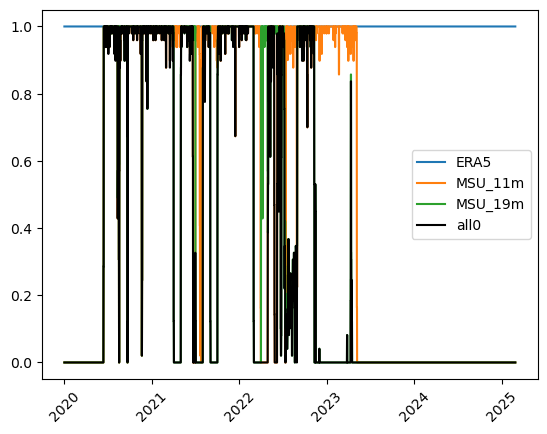

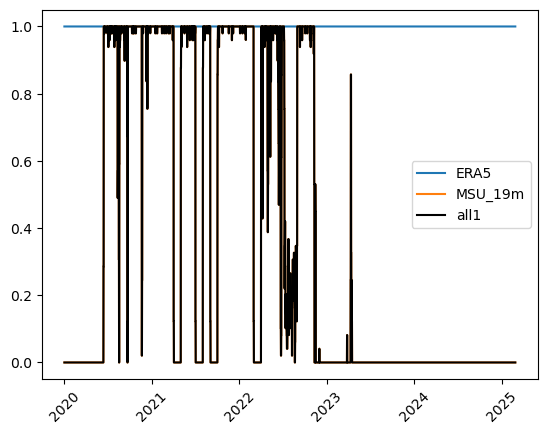

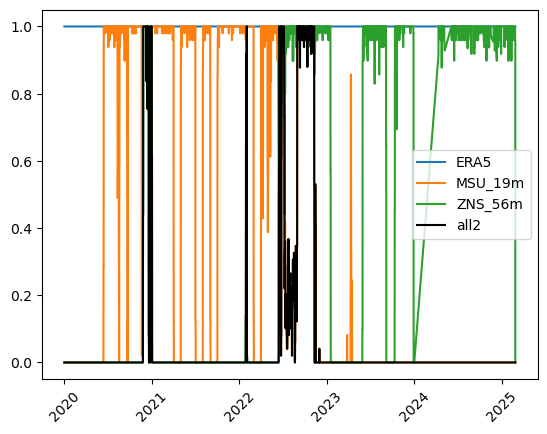

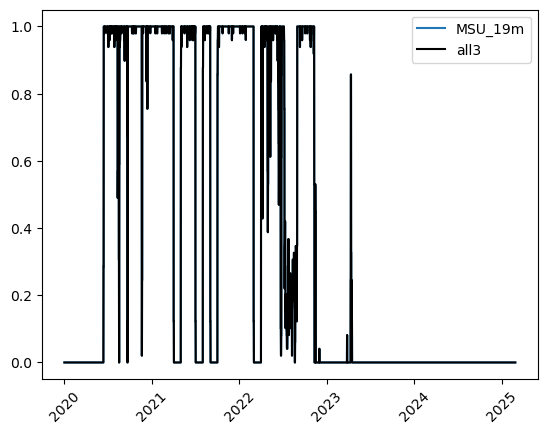

In [24]:
#matplotlib inline
#%matplotlib qt
sites = df4sites.keys()

def is_ok4day (df, unique_dates, is_ok_name):
    df['is_ok4day_' + is_ok_name] = np.zeros((df.shape[0],1))
    for unique_date in unique_dates:
        sel_times = slice (pd.Timestamp(unique_date), pd.Timestamp(unique_date) + pd.Timedelta(days=1))
        n = df[sel_times].shape[0]
        n_ok = np.sum(df[sel_times]['is_ok_' + is_ok_name])
        df.loc[sel_times, 'is_ok4day_' + is_ok_name] = n_ok/n
    return df
unique_dates = np.unique(df.index.date)

if city_name == 'Moscow':
    sites2draw_sets = [['ERA5', 'MSU_11m', 'MSU_19m'], ['ERA5', 'MSU_19m'], ['ERA5', 'MSU_19m', 'ZNS_56m'], ['MSU_19m']]
    vars2draw = ['Wind_vel', 'Qtau', 'Qh', 'Cd']
elif city_name == 'Tomsk':
    #sites2draw_sets = [['Oblkom', 'BEK'], ['Oblkom', 'IMCES40m']]
    sites2draw_sets = [['BEK','Oblkom'], ['IMCES40m', 'Oblkom'], ['BEK', 'IMCES40m', 'Oblkom'], ['BEK', 'IMCES40m', 'IMCES30m_mezo', 'Oblkom']] 
    #, ['Oblkom', 'IMCES_40m'], ['Oblkom', 'IMCES_40m', 'IMCES_MEZO_30m']]
    #sites2draw_sets = [['Oblkom', 'BEK', 'ERA5'], ['Oblkom', 'BEK', 'IMCES_40m'], ['Oblkom', 'IMCES_40m'], ['Oblkom', 'IMCES_40m', 'IMCES_MEZO_30m']]
    
    vars2draw = ['T_air', 'Wind_vel', 'Qtau', 'Qh', 'Cd'] #Wind_W
elif city_name == 'Beijing':
    #sites2draw_sets = [['ERA5', 'Beijing_47m', 'Beijing_80m', 'Xianghe_32m', 'Xianghe_80m']] 
    sites2draw_sets = [['Beijing_47m', 'Beijing_80m', 'Xianghe_32m', 'Xianghe_80m'],
                       ['Beijing_47m', 'Xianghe_32m'],
                       ['Beijing_80m', 'Xianghe_80m']] 
    
    #sites2draw_sets = [['Beijing_80m', 'Xianghe_80m'], ['Beijing_47m', 'Xianghe_32m'], ['Beijing_47m', 'Beijing_80m', 'Xianghe_32m', 'Xianghe_80m']] 
    vars2draw = ['Wind_vel', 'Qtau', 'Qh', 'Cd']



qc_var = 'qc_tot'

for site in sites:
    if site != 'ERA5':
        df['is_ok_' + site] = np.logical_and.reduce([~np.isnan(df[site + '_' + var]) & df[site + '_' + qc_var] for var in vars2draw])
    else:
        df['is_ok_' + site] = np.ones_like(df[site + '_' + vars2draw[0]])
    
    df = is_ok4day (df, unique_dates, site)

df = is_ok4day (df, unique_dates, site)

for i, sites2draw in enumerate(sites2draw_sets):
    display(sites2draw)
    df['is_ok_all' + str(i)] = np.logical_and.reduce([df['is_ok_' + site] for site in sites2draw])
    df = is_ok4day (df, unique_dates, 'all' + str(i))

    plt.figure()
    for site in sites2draw:
        plt.plot (df['is_ok4day_' + site], label = site)
    plt.plot(df['is_ok4day_all' + str(i)], color='black', label = 'all' + str(i))
    plt.legend()
    _ = plt.xticks(rotation = 45)

In [25]:


from calendar import monthrange
import matplotlib.ticker
#periods = [slice(pd.Timestamp(2022,m,1),pd.Timestamp(2022,m,1) + pd.Timedelta (days = monthrange(2022,m)[1]) - pd.Timedelta (hours=1)) for m in [11,12]] + \
#          [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in [5,6,7]]


#periods = [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in [7, 8,11,12]] + \
#          [slice(pd.Timestamp(2024,m,1),pd.Timestamp(2024,m,1) + pd.Timedelta (days = monthrange(2024,m)[1]) - pd.Timedelta (hours=1)) for m in [1,6]] #+ [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in [5,6,7]]

# periods = [slice(pd.Timestamp(2022,m,1),pd.Timestamp(2022,m,1) + pd.Timedelta (days = monthrange(2022,m)[1]) - pd.Timedelta (hours=1)) for m in range(12,13)] + \
#           [slice(pd.Timestamp(2023,m,1),pd.Timestamp(2023,m,1) + pd.Timedelta (days = monthrange(2023,m)[1]) - pd.Timedelta (hours=1)) for m in range(5,13)]  + \
#           [slice(pd.Timestamp(2024,m,1),pd.Timestamp(2024,m,1) + pd.Timedelta (days = monthrange(2024,m)[1]) - pd.Timedelta (hours=1)) for m in range(1,9)] #+ \
#           #[slice(pd.Timestamp(2024,8,1),pd.Timestamp(2024,8,6), slice(pd.Timestamp(2024,8,8),pd.Timestamp(2024,9,1)))]





if city_name == 'Moscow':
    periods = [slice(pd.Timestamp(2020,11,1),pd.Timestamp(2021,1,1)),
               slice(pd.Timestamp(2021,1,1),pd.Timestamp(2021,3,1)), 
               slice(pd.Timestamp(2021,6,1),pd.Timestamp(2021,9,1)), 
               slice(pd.Timestamp(2022,6,1),pd.Timestamp(2022,9,1))]
elif city_name == 'Beijing':
    periods = [slice(pd.Timestamp(2023,12,1),pd.Timestamp(2024,1,1)), 
               slice(pd.Timestamp(2024,1,1), pd.Timestamp(2024,2,1)),
               slice(pd.Timestamp(2024,6,1), pd.Timestamp(2024,7,1))
               ]
elif city_name == 'Tomsk':
    periods = [
               slice(pd.Timestamp(2022,12,1), pd.Timestamp(2023,1,1)),
               slice(pd.Timestamp(2023,6,1),  pd.Timestamp(2023,7,1)),
               slice(pd.Timestamp(2024,8,1),  pd.Timestamp(2024,9,1)),
               slice(pd.Timestamp(2024,12,1), pd.Timestamp(2025,1,1)), 
               slice(pd.Timestamp(2025,1,1),  pd.Timestamp(2025,2,1)), 
               slice(pd.Timestamp(2025,2,1),  pd.Timestamp(2025,3,1)), 
               slice(pd.Timestamp(2025,5,1),  pd.Timestamp(2025,6,1)), 
               slice(pd.Timestamp(2025,6,1),  pd.Timestamp(2025,7,1))]

    
    



In [27]:
%matplotlib inline

lang = 'en'

if lang == 'ru':
    vars2draw_labels = {'T_air'  : 'Температура воздуха $T, °C$',
                        'Wind_vel'  : 'Скорость ветра $V, м/с$',
                        #'w'  : 'Верт. скорость ветра, м/с',
                        'Qtau': 'Поток импульса $\\tau, кг\\cdot м^{-2}\\cdot c^{-1}$',
                        'Qh'  : 'Поток явного тепла $H, Вт\\cdotм^{-2}$',
                        'Qle' : 'Поток скрытого тепла $LE, Вт\\cdotм^{-2}$',
                        'Cd'  : 'Коэффициент обмена $C_d$'}
else:
    vars2draw_labels = {'T_air'  : 'Air temperature $T, °C$',
                        'Wind_vel'  : 'Wind speed $V, m/s$',
                        'Qtau': 'Momentum flux $\\tau, kg·m^{-2}·s^{-1}$',
                        'Qh'  : 'Sensible heat flux $H, W·m^{-2}$',
                        'Qle' : 'Latent heat flux $LE, W·m^{-2}$',
                        'Cd'  : 'Exchange coefficient $C_d$'}


y_lims = {'Wind_vel': [0,5], 
           'w':  [-0.6,0.6],
           'Qh': [-50, 200],
           'Qtau': [0,1],
           'Cd': [0, 0.1]}

if city_name == 'Moscow':
    site_names2draw = {s:s for s in ['MSU_19m', 'MSU_11m', 'ZNS_56m']}
    site_colors = {'MSU_19m':'red', 'MSU_11m':'orange', 'ZNS_56m':'blue'}
    site_styles = {}
    #vars2draw = ['T_air', 'Wind_vel', 'Qtau', 'Qh', 'Cd']
    vars2draw = ['Qtau', 'Qh', 'Cd']

elif city_name == 'Beijing':
    if lang == 'ru':
        site_names2draw = {'Xianghe_32m':'Фон (32 м)',
                           'Xianghe_80m':'Фон (80 м)',
                           'Beijing_47m': 'Город (47 м)', 
                           'Beijing_80m': 'Город (80 м)'}
    else:
        site_names2draw = {'Xianghe_32m':'Xianghe (32 m)',
                           'Xianghe_80m':'Xianghe (80 m)',
                           'Beijing_47m': 'Beijing (47 m)', 
                           'Beijing_80m': 'Beijing (80 m)'}

    site_colors = {'Xianghe_32m':'blue',
                   'Xianghe_80m':'lightblue',
                   'Beijing_47m': 'red',
                   'Beijing_80m': 'orange'}
    #vars2draw = ['Wind_vel', 'Qtau', 'Qh', 'Qle', 'Cd']
    vars2draw = ['Qtau', 'Qh', 'Qle', 'Cd']

    site_styles = {}
    y_lims['Qh'] = [-50, 260]
    y_lims['Qle'] = [-50, 260]
    y_lims['Cd'] = [0, 0.2]

elif city_name == 'Tomsk':

    #vars2draw = ['Wind_vel', 'Qtau', 'Qh', 'Qle', 'Cd']
    vars2draw = ['Qtau', 'Qh', 'Cd']
    
    if lang == 'ru':
        site_names2draw = {'BEK':'Фон (БЭК)',
                           'IMCES40m': 'Город (ИМКЭС, 40 м)', 
                           'IMCES30m': 'Город (ИМКЭС, 30 м)',
                           'IMCES30m_mezo': 'Город (ИМКЭС, мезонин, 30 м)', 
                           'Oblkom': 'Город (Облкомприроды)'}
    else:
        site_names2draw = {'BEK':'Rural (BEK, 30 m)',
                           'IMCES40m':      'Urban (IMCES, 40 m)', 
                           'IMCES30m':      'Urban (IMCES, 30 m)',
                           'IMCES30m_mezo': 'Urban (IMCES, 30 m, mezonin)', 
                           'Oblkom':        'Urban (Oblkom, 30 m)'}
    

    site_colors = {'BEK': 'blue', 
                   'IMCES40m': 'orange', 
                   'IMCES30m': 'orange',
                   'IMCES30m_mezo': 'orange', 
                   'Oblkom': 'red'}

    site_styles = {'IMCES30m': '--',
                   'IMCES30m_mezo': ':'}
    # site_colors = {'BEK': 'black', 
    #               'IMCES_40m': 'black', 
    #               'Oblkom': 'gray'}

    y_lims['Cd'] = [0, 0.05] 
    y_lims['Qtau'] = [0,0.8]
    y_lims['Qh'] = [-50,175]
    
    

site_names2draw ['ERA5'] = 'ERA5'
site_colors ['ERA5'] = 'black'

# site_colors = {'BEK': 'black', 
#                'IMCES_40m': 'black', 
#                'IMCES_30m': 'black',
#                'IMCES_MEZO_30m': 'black', 
#                'Oblkom': 'gray'}

# site_styles = {'BEK': '--', 
#                'IMCES_40m': '--', 
#                'IMCES_30m': ':',
#                'IMCES_MEZO_30m': ':', 
#                'Oblkom': '-'} 

# site_styles = {'BEK': '-', 
#                'IMCES_40m': '-', 
#                'IMCES_30m': '-',
#                'IMCES_MEZO_30m': '-', 
#                'Oblkom': '-'} 



save_dir = 'pics_new%s_%s'%(city_name, lang) + '_4INMconf' + '/'
#save_dir = 'pics4paper2_BW' + corr_str + '/'
plt.rcParams["font.size"] = 12

if not os.path.isdir(save_dir):
    os.mkdir (save_dir)

valid_data_frac = 0.9

for period in periods:

    df_sel = df[period]

    is_ok_count = np.zeros(len(sites2draw_sets))
    is_ok4sets = []
    for i_set, sites2draw_set in enumerate(sites2draw_sets):
        is_ok = df_sel['is_ok4day_all' + str(i_set)] > valid_data_frac
        is_ok_count[i_set] = np.sum(is_ok)
        is_ok4sets.append(is_ok)


    for i_set, sites2draw in enumerate(sites2draw_sets):
        if is_ok_count[i_set] == 0:
            continue
    
        is_ok = is_ok4sets[i_set]

        ok_idx  = np.where(is_ok)[0]
        bad_idx = np.where(~is_ok)[0]

        df_sel2 = df_sel.iloc[ok_idx, :]

        n_days = len(np.unique(df_sel2.index.date))

        #fig_name = '%s - %s, sites = %s'%(str(period.start.strftime('%Y.%m.%d'), str(period.stop.strftime('%Y.%m.%d'), str(sites2draw))))
        fig_name = '%s - %s, sites = %s, lim = %.2f'%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d')), str(sites2draw), valid_data_frac)
        
        
        for show_raw_data in [False,True]:
            fig, ax = plt.subplots(len(vars2draw), 1,  figsize = (10, 2.5* len(vars2draw)), sharex=True) 
            for i, var in enumerate(vars2draw):
                for site in sites2draw:
                    #df_sel[site + '_' + var].plot(ax = ax[i])
                    data_raw = df_sel[site + '_' + var]
                    data_filtered = data_raw.copy()
                    if site != 'ERA5':
                        data_filtered [~df_sel[site + '_' + qc_var].astype(bool)] = np.nan
                    if site in site_colors.keys():
                        p = ax[i].plot (df_sel.index, data_filtered, label = site, color = site_colors[site])
                    else:
                        p = ax[i].plot (df_sel.index, data_filtered, label = site) #, color = site_colors[site])
                    if show_raw_data:
                        c = p[0].get_color()
                        p = ax[i].plot (df_sel.index, data_raw, color = c, alpha = 0.5)
                        #ax[i].plot(df_sel.index[~df_sel[site + '_filter_passed']], data_raw [site + '_filter_passed'], 'ok')
                    
                ax[i].set_ylabel(vars2draw_labels[var])
                y_lim = list(ax[i].get_ylim())
                
                ok_indicator = np.ones_like(df_sel['is_ok4day_all' + str(i_set)])
                ok_indicator[bad_idx] = np.nan
        
                ax[i].fill_between (df_sel.index, ok_indicator*y_lim[0], ok_indicator*y_lim[1], alpha = 0.25, color = 'green') 
                ax[i].set_ylim(y_lim)
                ax[i].set_xlim((period.start, period.stop))

            plt.suptitle('%s - %s'%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d'))))
            plt.legend()
            plt.savefig (save_dir + 'ts' + fig_name + '_raw=%d'%show_raw_data + corr_name + '_qc.png', dpi=300)
            plt.close()

        fig, ax = plt.subplots(1, len(vars2draw), figsize = (4 * len(vars2draw), 4.2))
        plt.subplots_adjust (left = 0.06, wspace = 0.4, right = 0.99, bottom = 0.25)
        
        df4fig = pd.DataFrame()
        for i, var in enumerate(vars2draw):
            daily_means = {}
            for site in sites2draw:
                data_raw = df_sel2[site + '_' + var]
                data_filtered = data_raw.copy()
                if site!= 'ERA5':
                    data_filtered [~df_sel[site + '_' + qc_var].astype(bool)] = np.nan
                #data_filtered [~df_sel[site + '_' + qc_var].astype(bool)] = np.nan

                hour_means = data_filtered.groupby([df_sel2.index.hour]).mean()
                hour_stds = data_filtered.groupby([df_sel2.index.hour]).std()
                
                df4fig[var + '_' + site] = hour_means
                #ax[i].fill_between(hour_means.index, hour_means - hour_stds, hour_means + hour_stds, color = site_colors[site], alpha = 0.5)
                if site in site_colors.keys():
                    ax[i].plot(hour_means.index, hour_means, label=site_names2draw[site], color = site_colors[site], linestyle = site_styles[site] if site in site_styles.keys() else '-', linewidth = 2) 
                else:
                    ax[i].plot(hour_means.index, hour_means, label=site_names2draw[site], linestyle = site_styles[site] if site in site_styles.keys() else '-', linewidth = 2) 
                
                if var == 'w':
                    ax[i].plot(hour_means.index, hour_stds, '--', label=site_names2draw[site], color = site_colors[site]) 

                daily_means[site] = hour_means.mean()
                
            #if i == 0:
            #ax[i].set_title(var)
            ax[i].set_ylabel(vars2draw_labels[var], labelpad = 2, fontsize='large', fontweight='bold')
            ax[i].set_xticks(np.arange(0,24+1,6)) 
            ax[i].set_xlabel('Время суток, ч' if lang == 'ru' else 'Daytime, h', fontsize='large', fontweight='bold')
            ax[i].set_xlim((0,24))

            y_lim = list(ax[i].get_ylim())
            x_lim = list(ax[i].get_ylim())
            
            if var in ['Cd', 'Qtau', 'Wind_vel']:
                y_lim[0] = 0

            if var in y_lims.keys():
                y_lim = y_lims[var]    

            
            ax[i].set_ylim(y_lim)

            
            #if var in ['Qh', 'Qtau', 'Qle', 'Cd', 'Wind_vel']:
            fmt = '%.1f' if var in ['Qh', 'Wind_vel', 'T_air'] else '%.2f'
            for i_site, site in enumerate (daily_means.keys()):
                ax[i].annotate (fmt%daily_means[site], (0.95,1-0.08*(1+i_site)), xycoords='axes fraction', ha='right', color = site_colors[site], weight='bold', backgroundcolor=[1,1,1,0.5])
        
            if var == 'T_air':
                ax[i].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(1))

            ax[i].grid(zorder=0)
            ax[i].axhline(y=0, zorder=0, color = 'black', linewidth = 0.75)

        handles, labels = ax[0].get_legend_handles_labels()
        plt.figlegend(handles, labels, loc="lower center", ncol=len (sites2draw), fontsize='large')
        
        version_str = '' #'(new)' if corr_name == 'test2' else '(old)'

        if lang == 'ru':
            plt.suptitle('%s - %s, осреднение за %d дней %s'%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d')), n_days, version_str), fontsize='large')
        else:
            plt.suptitle('%s - %s, averaging over %d days %s'%(str(period.start.strftime('%Y.%m.%d')), str(period.stop.strftime('%Y.%m.%d')), n_days, version_str), fontsize='large')
        
        plt.savefig (save_dir + 'mean_diurnal_turn_' + fig_name + corr_name + '_qc.png', dpi=300)
        
        df4fig.to_csv (save_dir + 'mean_diurnal_turn_' + fig_name + corr_name + '.csv', sep=';')
        plt.close()
        #break



In [127]:
sys.exit()
pd.options.plotting.backend = "plotly"
df2draw = df[[col for col in df.columns if 'Qh' in col and '30m' not in col]]


for col in df2draw.columns:
    qc_col = df[col.replace('Qh', 'qc')]
    df2draw.loc[qc_col == 0, col] = np.nan #df2draw[col].where(qc_col)

df2draw_renamed = df2draw.rename(columns={col: site_names2draw[col.replace('_Qh', '')] for col in df2draw.columns})

fig = df2draw_renamed['2022.01.01':].plot(color_discrete_sequence=[site_colors[col.replace('_Qh', '')] for col in df2draw.columns])
fig.update_layout(yaxis_title='Sensible heat flux H, W·m-2', xaxis_title = '')
fig.show()




NameError: name 'sys' is not defined

C:\Users\mvar9\AppData\Local\Temp\ipykernel_28296\1363803666.py:23: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`

C:\Users\mvar9\AppData\Local\Temp\ipykernel_28296\1363803666.py:27: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`

C:\Users\mvar9\AppData\Local\Temp\ipykernel_28296\1363803666.py:35: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`

C:\Users\mvar9\AppData\Local\Temp\ipykernel_28296\1363803666.py:38: FutureWarning:

Series.__g

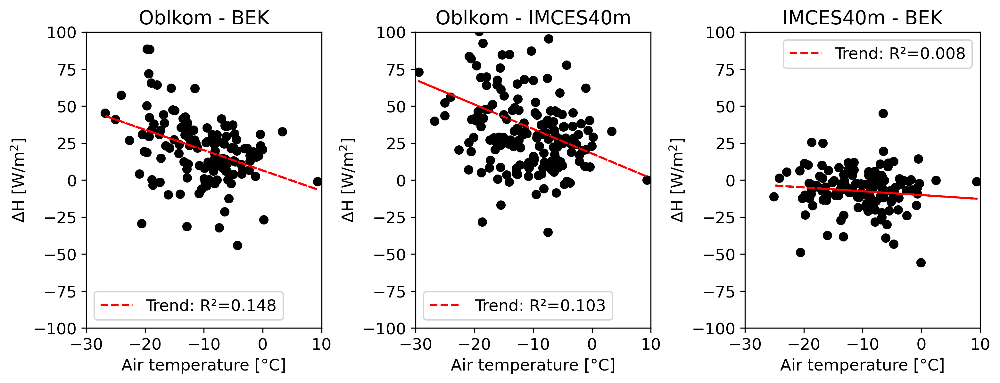

In [ ]:
from scipy import stats

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

#idx = np.where((df.index > pd.Timestamp (2024, 8, 1)) & np.isin (df.index.month, [11,12,1,2,3]))[0] # & np.isin (df.index.hour, [23,0,1,2,3]))[0]

pairs = [('Oblkom', 'BEK'), ('Oblkom', 'IMCES40m'), ('IMCES40m', 'BEK')]

df_1h = df.resample('1D').mean()
df2draw_1h = df2draw.resample('1D').mean()

idx = np.where((df_1h.index > pd.Timestamp (2022, 8, 1)) & np.isin (df_1h.index.month, [11,12,1,2]))[0] # & np.isin (df.index.hour, [23,0,1,2,3]))[0]

fig, axs = plt.subplots (1, len(pairs), figsize=(12, 4))
plt.subplots_adjust (wspace=0.4)

for pair in pairs:
    plt.sca (axs[pairs.index(pair)])
    urb_site = pair[0]
    rur_site = pair[1]

    x = df_1h[f'{urb_site}_T_air'][idx]
    #x = df_1h[f'{urb_site}_Wind_vel'][idx]

    
    y = df2draw_1h[f'{urb_site}_Qh'][idx] - df2draw_1h[f'{rur_site}_Qh'][idx]

    # idx_sort = np.argsort(x)
    # x = x[idx_sort]
    # y = y[idx_sort]

    idx_xy = np.where (~np.isnan(x) & ~np.isnan(y))[0]

    slope, intercept, r_value, p_value, std_err = stats.linregress(x[idx_xy], y[idx_xy])

    #plt.hexbin (x, y, mincnt=1, gridsize=40)
    plt.plot(x[idx_xy], y[idx_xy], 'ok')

    line = slope * x[idx_xy] + intercept
    plt.plot(x[idx_xy], line, 'r--', label=f'Trend: R²={r_value**2:.3f}')
             
    plt.xlabel (r'Air temperature [°C]')
    plt.ylabel (r'$\Delta$H [W/m$^2$]')
    plt.title (f'{urb_site} - {rur_site}')
    plt.xlim([-30,10])
    plt.ylim([-100,100])
    plt.legend()



C:\Users\mvar9\AppData\Local\Temp\ipykernel_27020\1841009529.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sel['delta_Qh'] = df_sel['Oblkom_Qh'] - df_sel['BEK_Qh']
C:\Users\mvar9\AppData\Local\Temp\ipykernel_27020\1841009529.py:7: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  plt.plot (df_sel['Oblkom_Wind_vel'].resample('1H').mean(), df_sel['delta_Qh'].resample('1H').mean(), 'o')


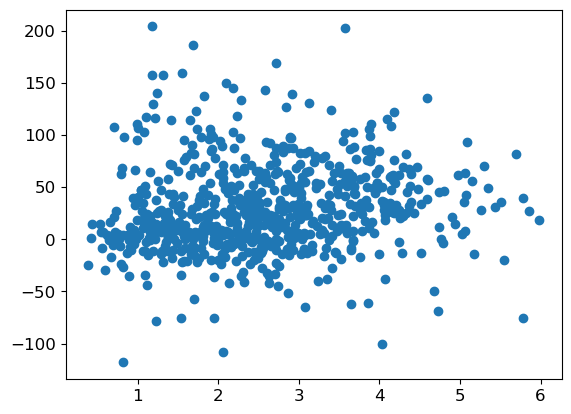

In [ ]:
#df_sel = df['2022-11-01':'2023-02-02']
#df_sel = df['2024-10-01':'2024-11-02']

df_sel['delta_Qh'] = df_sel['Oblkom_Qh'] - df_sel['BEK_Qh']
df_sel.loc[(~df_sel['Oblkom_filter_passed'] | ~df_sel['BEK_filter_passed']), 'delta_Qh'] = np.nan

plt.plot (df_sel['Oblkom_Wind_vel'].resample('1H').mean(), df_sel['delta_Qh'].resample('1H').mean(), 'o')